In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [22]:
baseball = pd.read_csv("cleaned_batting_stats.csv")
cleaned_baseball = baseball.copy()

In [23]:
cleaned_baseball.head(5)

,Rk,Player,Age,Team,Lg,WAR,G,PA,AB,R,...,TB,GIDP,HBP,SH,SF,IBB,Pos,Awards,Year,RowNum
0,357.0,A.J. Ellis,35.0,2TM,NL,-0.1,64.0,196.0,171.0,11.0,...,51.0,5.0,2.0,3.0,1.0,2.0,2/H,NaN,2016,1
1,416.0,AJ Pollock,35.0,2TM,2LG,-0.7,54.0,144.0,133.0,15.0,...,41.0,1.0,0.0,0.0,2.0,0.0,7DH/89,NaN,2023,1
2,284.0,Aaron Hicks#,33.0,2TM,AL,0.5,93.0,312.0,269.0,44.0,...,103.0,3.0,0.0,0.0,1.0,1.0,879H/D,NaN,2023,1
3,193.0,Aaron Hill,34.0,2TM,2LG,1.5,125.0,429.0,378.0,48.0,...,143.0,6.0,3.0,0.0,4.0,2.0,54H/D,NaN,2016,1
4,301.0,Abraham Almonte#,26.0,2TM,2LG,0.8,82.0,258.0,232.0,36.0,...,95.0,5.0,0.0,3.0,2.0,0.0,8H/79D,NaN,2015,1


In [24]:
cleaned_baseball.columns

Index(['Rk', 'Player', 'Age', 'Team', 'Lg', 'WAR', 'G', 'PA', 'AB', 'R', 'H',
       '2B', '3B', 'HR', 'RBI', 'SB', 'CS', 'BB', 'SO', 'BA', 'OBP', 'SLG',
       'OPS', 'OPS+', 'rOBA', 'Rbat+', 'TB', 'GIDP', 'HBP', 'SH', 'SF', 'IBB',
       'Pos', 'Awards', 'Year', 'RowNum'],
      dtype='object')

In [25]:
cleaned_baseball.dtypes

Rk        float64
Player     object
Age       float64
Team       object
Lg         object
WAR       float64
G         float64
PA        float64
AB        float64
R         float64
H         float64
2B        float64
3B        float64
HR        float64
RBI       float64
SB        float64
CS        float64
BB        float64
SO        float64
BA        float64
OBP       float64
SLG       float64
OPS       float64
OPS+      float64
rOBA      float64
Rbat+     float64
TB        float64
GIDP      float64
HBP       float64
SH        float64
SF        float64
IBB       float64
Pos        object
Awards     object
Year        int64
RowNum      int64
dtype: object

**data cleaning**
<br>drop columns of Rk and RowNum</br>

In [26]:
cleaned_baseball = cleaned_baseball.drop(columns=["Rk", "RowNum", "Pos"])
cleaned_baseball

,Player,Age,Team,Lg,WAR,G,PA,AB,R,H,...,rOBA,Rbat+,TB,GIDP,HBP,SH,SF,IBB,Awards,Year
0,A.J. Ellis,35.0,2TM,NL,-0.1,64.0,196.0,171.0,11.0,37.0,...,0.279,62.0,51.0,5.0,2.0,3.0,1.0,2.0,NaN,2016
1,AJ Pollock,35.0,2TM,2LG,-0.7,54.0,144.0,133.0,15.0,22.0,...,0.233,48.0,41.0,1.0,0.0,0.0,2.0,0.0,NaN,2023
2,Aaron Hicks#,33.0,2TM,AL,0.5,93.0,312.0,269.0,44.0,68.0,...,0.328,106.0,103.0,3.0,0.0,0.0,1.0,1.0,NaN,2023
3,Aaron Hill,34.0,2TM,2LG,1.5,125.0,429.0,378.0,48.0,99.0,...,0.321,88.0,143.0,6.0,3.0,0.0,4.0,2.0,NaN,2016
4,Abraham Almonte#,26.0,2TM,2LG,0.8,82.0,258.0,232.0,36.0,58.0,...,0.317,86.0,95.0,5.0,0.0,3.0,2.0,0.0,NaN,2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4497,Yadiel HernÃ¡ndez*,34.0,WSN,NL,0.6,94.0,327.0,305.0,30.0,82.0,...,0.323,109.0,125.0,9.0,1.0,0.0,2.0,0.0,NaN,2022
4498,Yan Gomes,32.0,WSN,NL,0.7,30.0,119.0,109.0,14.0,31.0,...,0.351,115.0,51.0,1.0,1.0,0.0,3.0,0.0,NaN,2020
4499,Yan Gomes,31.0,WSN,NL,1.4,97.0,358.0,314.0,36.0,70.0,...,0.311,79.0,122.0,7.0,5.0,0.0,1.0,6.0,NaN,2019
4500,Yan Gomes,33.0,WSN,NL,2.0,63.0,235.0,218.0,30.0,59.0,...,0.337,111.0,99.0,12.0,4.0,0.0,0.0,3.0,NaN,2021


**Check Data Types for Numeric Columns**

Age       float64
WAR       float64
G         float64
PA        float64
AB        float64
R         float64
H         float64
2B        float64
3B        float64
HR        float64
RBI       float64
SB        float64
CS        float64
BB        float64
SO        float64
OPS+      float64
TB        float64
GIDP      float64
HBP       float64
SH        float64
SF        float64
IBB       float64

In [27]:
numerics = ["Age", "G", "PA", "AB", "R", "H", "2B", "3B", "HR", "RBI", "SB", "CS", "BB", "SO", "OPS+", "TB", "GIDP", "HBP", "SH", "SF", "IBB", "Rbat+"]

In [28]:
cleaned_baseball[numerics] = cleaned_baseball[numerics].astype("int64")
cleaned_baseball.head(5)

,Player,Age,Team,Lg,WAR,G,PA,AB,R,H,...,rOBA,Rbat+,TB,GIDP,HBP,SH,SF,IBB,Awards,Year
0,A.J. Ellis,35,2TM,NL,-0.1,64,196,171,11,37,...,0.279,62,51,5,2,3,1,2,NaN,2016
1,AJ Pollock,35,2TM,2LG,-0.7,54,144,133,15,22,...,0.233,48,41,1,0,0,2,0,NaN,2023
2,Aaron Hicks#,33,2TM,AL,0.5,93,312,269,44,68,...,0.328,106,103,3,0,0,1,1,NaN,2023
3,Aaron Hill,34,2TM,2LG,1.5,125,429,378,48,99,...,0.321,88,143,6,3,0,4,2,NaN,2016
4,Abraham Almonte#,26,2TM,2LG,0.8,82,258,232,36,58,...,0.317,86,95,5,0,3,2,0,NaN,2015


**Create booleans for awards**

In [29]:
cleaned_baseball["Rookie Of The Year"] = np.where(cleaned_baseball["Awards"].str.contains("ROY-1", na=False), 1, 0).astype(bool)
cleaned_baseball["All Star Appearance"] = np.where(cleaned_baseball["Awards"].str.contains("AS", na=False), 1, 0).astype(bool)
cleaned_baseball["MVP"] = np.where(cleaned_baseball["Awards"].str.contains("MVP-1", na=False), 1, 0).astype(bool)
cleaned_baseball["Sliver Slugger"] = np.where(cleaned_baseball["Awards"].str.contains("SS", na=False), 1, 0).astype(bool)
cleaned_baseball["Considered for Rookie Of The Year"] = np.where(cleaned_baseball["Awards"].str.contains("ROY", na=False), 1, 0).astype(bool)
cleaned_baseball["Considered for MVP"] = np.where(cleaned_baseball["Awards"].str.contains("MVP", na=False), 1, 0).astype(bool)

**Create Boolean for Players who played for more than one team**

In [30]:
multiple = ["2TM", "3TM", "4TM"]
cleaned_baseball["Played For Multiple Teams"] = np.where(cleaned_baseball["Team"].isin(multiple), 1, 0).astype(bool)

**Remove Weird Asterisks and Funky Naming Conventions**
<br>-remove # </br>
<br>-remove accents </br> 
<br>-remove weird encoding </br>
<br>-remove *
<br>-remove whitespace </br>

In [31]:
import unicodedata

def fix_mojibake(s):
    if not isinstance(s, str):
        return s
    try:
        return s.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s

def strip_accents(s):
    if not isinstance(s, str):
        return s
    return ''.join(
        c for c in unicodedata.normalize('NFKD', s)
        if not unicodedata.combining(c)
    )

In [32]:
cleaned_baseball["Player"] = (
    cleaned_baseball["Player"]
        .apply(fix_mojibake)        # repair encoding first
        .apply(strip_accents)       # then strip diacritics
        .str.replace(r"[#*]", "", regex=True)  # then drop handedness markers
        .str.strip()                # tidy any leftover whitespace
)

In [33]:
cleaned_baseball.dtypes

Player                                object
Age                                    int64
Team                                  object
Lg                                    object
WAR                                  float64
G                                      int64
PA                                     int64
AB                                     int64
R                                      int64
H                                      int64
2B                                     int64
3B                                     int64
HR                                     int64
RBI                                    int64
SB                                     int64
CS                                     int64
BB                                     int64
SO                                     int64
BA                                   float64
OBP                                  float64
SLG                                  float64
OPS                                  float64
OPS+      

**Which team employed the most amount of position players**
- records with 2TM, 3TM and 4TM are removed for this analysis
- smaller markets like tampa bay, minnesota and cleveland are towards the top as they don't have the funds to keep players when their contracts are up

In [38]:
players_without_multiple = cleaned_baseball[~cleaned_baseball["Team"].isin(multiple)]

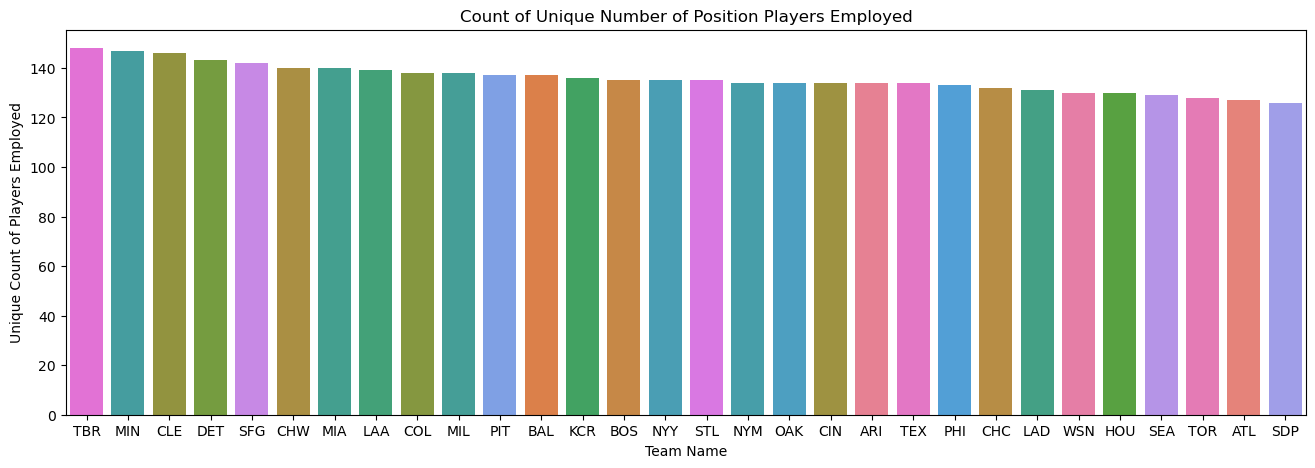

In [50]:
order = players_without_multiple["Team"].value_counts().index
plt.figure(figsize=(16, 5))
sns.countplot(data=players_without_multiple, x="Team", order=order, hue="Team")
plt.title("Count of Unique Number of Position Players Employed")
plt.xlabel("Team Name")
plt.ylabel("Unique Count of Players Employed")
plt.show()